<a href="https://colab.research.google.com/github/Chetalam/cnn-skin-cancer-classification/blob/main/notebooks/05_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 — CNN Transfer Learning

Train MobileNetV2, EfficientNet-B0 and ResNet50 using the grouped splits from notebook 4. Class order is BCC, Melanoma, SCC. Use training-only class weights and augmentation. Select model checkpoints using validation macro F1. Reserve the test set for notebook 6.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import json
import shutil
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import display

print('TensorFlow:', tf.__version__)
print('Keras:', getattr(tf.keras, '__version__', 'bundled with TensorFlow'))
gpus = tf.config.list_physical_devices('GPU')
print('Available GPUs:', gpus)
if not gpus:
    raise RuntimeError('Enable the T4 GPU before continuing.')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
HEAD_EPOCHS = 6
FINE_TUNE_EPOCHS = 8
CLASS_NAMES = ['BCC', 'Melanoma', 'SCC']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
PROJECT_ROOT = Path('/content/drive/MyDrive/cnn-skin-cancer-classification')
SPLIT_ROOT = PROJECT_ROOT / 'Datasets' / 'Splits'
MODEL_ROOT = PROJECT_ROOT / 'Models' / 'Transfer_Learning'
REPORT_ROOT = PROJECT_ROOT / 'Reports' / 'Training'
LOCAL_ROOT = Path('/content/skin_cancer_training_images')
for folder in [MODEL_ROOT, REPORT_ROOT, LOCAL_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

def write_json(path, value):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2), encoding='utf-8')
    temporary.replace(path)

Mounted at /content/drive
TensorFlow: 2.21.0
Keras: 3.13.2
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
frames = {}
manifest_hashes = {}
for split in ['train', 'validation', 'test']:
    path = SPLIT_ROOT / f'{split}_metadata.csv'
    if not path.is_file():
        raise FileNotFoundError(path)
    manifest_hashes[split] = hashlib.sha256(path.read_bytes()).hexdigest()
    frame = pd.read_csv(path, dtype={'patient_id': 'string', 'lesion_id': 'string'})
    required = {'dataset', 'image_id', 'class_label', 'image_path', 'image_hash', 'group_id', 'label_index', 'split'}
    if not required.issubset(frame.columns):
        raise ValueError(f'{split}: required split columns are missing.')
    if not frame['split'].eq(split).all():
        raise ValueError(f'{split}: incorrect split assignments.')
    if set(frame['class_label']) != set(CLASS_NAMES):
        raise ValueError(f'{split}: expected all three classes.')
    expected_labels = frame['class_label'].map(CLASS_TO_INDEX)
    if not expected_labels.eq(frame['label_index']).all():
        raise ValueError(f'{split}: class order differs from notebook 4.')
    frames[split] = frame

combined = pd.concat(frames.values(), ignore_index=True)
assert len(combined) == 2703
assert not combined.duplicated(['dataset', 'image_id']).any()
assert combined.groupby('group_id')['split'].nunique().max() == 1
assert combined.groupby('image_hash')['split'].nunique().max() == 1
pad = combined[combined['dataset'] == 'PAD-UFES-20']
assert pad['patient_id'].notna().all()
assert pad.groupby('patient_id')['split'].nunique().max() == 1
lesions = combined.dropna(subset=['lesion_id'])
assert lesions.groupby(['dataset', 'lesion_id'])['split'].nunique().max() == 1

train_frame = frames['train'].copy()
val_frame = frames['validation'].copy()
train_counts = train_frame['label_index'].value_counts().reindex(range(3))
CLASS_WEIGHTS = {
    index: float(len(train_frame) / (3 * train_counts[index]))
    for index in range(3)
}
print('Training records:', len(train_frame))
print('Validation records:', len(val_frame))
print('Test records reserved for notebook 6:', len(frames['test']))
print('Class order:', CLASS_TO_INDEX)
print('Training-only class weights:', CLASS_WEIGHTS)
display(pd.crosstab(combined['split'], combined['class_label']))

# Separate output folders when data or training settings change.
SETTINGS = {
    'seed': SEED, 'image_size': list(IMAGE_SIZE), 'batch_size': BATCH_SIZE,
    'head_epochs': HEAD_EPOCHS, 'fine_tune_epochs': FINE_TUNE_EPOCHS,
    'class_names': CLASS_NAMES, 'manifest_hashes': manifest_hashes,
    'tensorflow_version': tf.__version__, 'head_learning_rate': 0.001,
    'fine_tune_learning_rate': 0.00001, 'fine_tune_fraction': 0.20,
    'augmentation': 'flip_horizontal_vertical; rotation_0.05; zoom_0.10; brightness_0.10',
}
RUN_ID = hashlib.sha256(json.dumps(SETTINGS, sort_keys=True).encode()).hexdigest()[:12]
RUN_MODELS = MODEL_ROOT / RUN_ID
RUN_REPORTS = REPORT_ROOT / RUN_ID
RUN_MODELS.mkdir(parents=True, exist_ok=True)
RUN_REPORTS.mkdir(parents=True, exist_ok=True)
write_json(RUN_REPORTS / 'training_settings.json', SETTINGS)
print('Training run:', RUN_ID)

Training records: 1905
Validation records: 390
Test records reserved for notebook 6: 408
Class order: {'BCC': 0, 'Melanoma': 1, 'SCC': 2}
Training-only class weights: {0: 0.6642259414225942, 1: 0.7753357753357754, 2: 4.884615384615385}


class_label,BCC,Melanoma,SCC
split,,,
test,197,182,29
train,956,819,130
validation,200,164,26


Training run: 77751764c605


train: 250/1905 copied
train: 500/1905 copied
train: 750/1905 copied
train: 1000/1905 copied
train: 1250/1905 copied
train: 1500/1905 copied
train: 1750/1905 copied
train: local images ready
validation: 250/390 copied
validation: local images ready


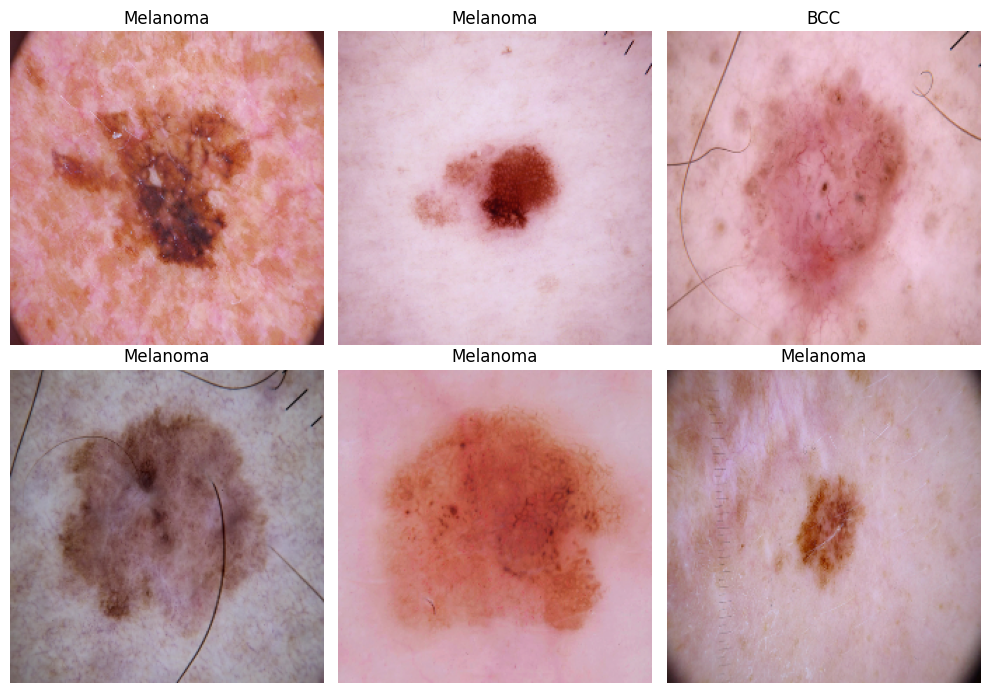

In [3]:
# Copy only training and validation images; test images are not loaded.
for split, frame in [('train', train_frame), ('validation', val_frame)]:
    local_paths = []
    for position, row in enumerate(frame.itertuples(index=False)):
        source = Path(row.image_path)
        if not source.is_file():
            raise FileNotFoundError(source)
        if source.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.bmp'}:
            raise ValueError(f'Unsupported training image format: {source}')
        key = hashlib.sha256(str(source).encode()).hexdigest()
        destination = LOCAL_ROOT / (key + source.suffix.lower())
        if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
            temporary = destination.with_suffix(destination.suffix + '.tmp')
            shutil.copyfile(source, temporary)
            temporary.replace(destination)
        local_paths.append(str(destination))
        if (position + 1) % 250 == 0:
            print(f'{split}: {position + 1}/{len(frame)} copied')
    frame['local_path'] = local_paths
    print(f'{split}: local images ready')

def decode_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(tf.cast(image, tf.float32), IMAGE_SIZE, method='bilinear')
    return image, label

def raw_dataset(frame):
    ds = tf.data.Dataset.from_tensor_slices((
        frame['local_path'].to_numpy(dtype=str),
        frame['label_index'].to_numpy(dtype=np.int32),
    ))
    return ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).cache()

RAW_TRAIN = raw_dataset(train_frame)
RAW_VAL = raw_dataset(val_frame)
# Fully populate caches once, before model training.
for _ in RAW_TRAIN.batch(BATCH_SIZE):
    pass
for _ in RAW_VAL.batch(BATCH_SIZE):
    pass
VAL_LABELS = val_frame['label_index'].to_numpy(dtype=np.int32)
images, labels = next(iter(RAW_TRAIN.batch(6)))
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for axis, image, label in zip(axes.flat, images.numpy(), labels.numpy()):
    axis.imshow(np.clip(image, 0, 255).astype('uint8'))
    axis.set_title(CLASS_NAMES[int(label)])
    axis.axis('off')
plt.tight_layout()
plt.show()

In [4]:
MODEL_SPECS = {
    'MobileNetV2': (tf.keras.applications.MobileNetV2, tf.keras.applications.mobilenet_v2.preprocess_input, 'mobilenet_v2'),
    'EfficientNetB0': (tf.keras.applications.EfficientNetB0, tf.keras.applications.efficientnet.preprocess_input, 'efficientnet_b0'),
    'ResNet50': (tf.keras.applications.ResNet50, tf.keras.applications.resnet50.preprocess_input, 'resnet50'),
}

def model_datasets(name):
    preprocess = MODEL_SPECS[name][1]
    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
        tf.keras.layers.RandomRotation(0.05, fill_mode='reflect', seed=SEED + 1),
        tf.keras.layers.RandomZoom(0.10, fill_mode='reflect', seed=SEED + 2),
        tf.keras.layers.RandomBrightness(0.10, value_range=(0, 255), seed=SEED + 3),
    ])
    def prepare_training(images, labels):
        images = augmentation(images, training=True)
        return preprocess(tf.clip_by_value(images, 0.0, 255.0)), labels
    def prepare_validation(images, labels):
        return preprocess(images), labels
    train_ds = RAW_TRAIN.shuffle(len(train_frame), seed=SEED, reshuffle_each_iteration=True)
    train_ds = train_ds.batch(BATCH_SIZE).map(prepare_training, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    val_ds = RAW_VAL.batch(BATCH_SIZE).map(prepare_validation, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    return train_ds, val_ds

def classification_scores(labels, probabilities):
    predicted = probabilities.argmax(axis=1)
    matrix = np.zeros((3, 3), dtype=np.int64)
    np.add.at(matrix, (labels, predicted), 1)
    true_positive = np.diag(matrix).astype(float)
    precision = np.divide(true_positive, matrix.sum(axis=0), out=np.zeros(3), where=matrix.sum(axis=0) != 0)
    recall = np.divide(true_positive, matrix.sum(axis=1), out=np.zeros(3), where=matrix.sum(axis=1) != 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(3), where=(precision + recall) != 0)
    return float(f1.mean()), float((labels == predicted).mean())

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )

class ValidationCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, name, val_ds, model_dir, report_dir):
        super().__init__()
        self.name = name
        self.val_ds = val_ds
        self.model_dir = model_dir
        self.report_dir = report_dir
        self.best = -1.0
        self.best_accuracy = None
        self.best_phase = None
        self.best_epoch = None
        self.phase = 'head'
        self.rows = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        probabilities = self.model.predict(self.val_ds, verbose=0)
        macro_f1, accuracy = classification_scores(VAL_LABELS, probabilities)
        logs['val_macro_f1'] = macro_f1
        self.rows.append({'phase': self.phase, 'epoch': epoch + 1, **{key: float(value) for key, value in logs.items()}})
        pd.DataFrame(self.rows).to_csv(self.report_dir / 'training_history.csv', index=False)
        print(f' — validation macro F1: {macro_f1:.4f}')
        if macro_f1 > self.best:
            self.best = macro_f1
            self.best_accuracy = accuracy
            self.best_phase = self.phase
            self.best_epoch = epoch + 1
            self.model.save(self.model_dir / 'best.keras')
            self.model.save_weights(self.model_dir / 'best.weights.h5')
            write_json(self.model_dir / 'checkpoint.json', {
                'validation_macro_f1': macro_f1, 'validation_accuracy': accuracy,
                'phase': self.phase, 'epoch': epoch + 1, 'class_names': CLASS_NAMES,
            })
            print('Best checkpoint saved to Drive.')

def stop_callback():
    return tf.keras.callbacks.EarlyStopping(monitor='val_macro_f1', mode='max', patience=3, restore_best_weights=False)

def train_one_model(name):
    model_dir = RUN_MODELS / name
    report_dir = RUN_REPORTS / name
    model_dir.mkdir(parents=True, exist_ok=True)
    report_dir.mkdir(parents=True, exist_ok=True)
    metadata_path = model_dir / 'metadata.json'
    if metadata_path.is_file():
        saved = json.loads(metadata_path.read_text())
        if saved.get('training_complete') and saved.get('run_id') == RUN_ID and (model_dir / 'best.keras').is_file():
            print(name, 'already complete for this run; skipping.')
            return saved
    # Never overwrite an incomplete attempt: retain its checkpoints/history.
    if (model_dir / 'best.keras').exists() or (report_dir / 'training_history.csv').exists():
        stamp = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
        model_dir.rename(RUN_MODELS / f'{name}_interrupted_{stamp}')
        report_dir.rename(RUN_REPORTS / f'{name}_interrupted_{stamp}')
        model_dir.mkdir()
        report_dir.mkdir()

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    train_ds, val_ds = model_datasets(name)
    constructor, _, preprocess_name = MODEL_SPECS[name]
    base = constructor(weights='imagenet', include_top=False, input_shape=(*IMAGE_SIZE, 3))
    base.trainable = False
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name='preprocessed_image')
    features = base(inputs, training=False)
    features = tf.keras.layers.GlobalAveragePooling2D()(features)
    features = tf.keras.layers.Dropout(0.30, seed=SEED)(features)
    outputs = tf.keras.layers.Dense(3, activation='softmax', name='class_scores')(features)
    model = tf.keras.Model(inputs, outputs, name=name + '_skin_classifier')
    monitor = ValidationCheckpoint(name, val_ds, model_dir, report_dir)
    started = time.time()

    print('\nTRAINING CLASSIFICATION HEAD:', name)
    compile_model(model, 0.001)
    model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
              class_weight=CLASS_WEIGHTS, callbacks=[monitor, stop_callback()], verbose=2)
    model.load_weights(model_dir / 'best.weights.h5')

    print('\nFINE-TUNING:', name)
    base.trainable = True
    cutoff = int(len(base.layers) * 0.80)
    for index, layer in enumerate(base.layers):
        layer.trainable = index >= cutoff and not isinstance(layer, tf.keras.layers.BatchNormalization)
    compile_model(model, 0.00001)
    monitor.phase = 'fine_tune'
    model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
              class_weight=CLASS_WEIGHTS, callbacks=[monitor, stop_callback()], verbose=2)

    # Validate serialization: loaded best model must reproduce its weights.
    model.load_weights(model_dir / 'best.weights.h5')
    reference_batch, _ = next(iter(val_ds))
    reference_scores = model.predict(reference_batch, verbose=0)
    loaded = tf.keras.models.load_model(model_dir / 'best.keras', compile=False)
    reloaded_scores = loaded.predict(reference_batch, verbose=0)
    np.testing.assert_allclose(reference_scores, reloaded_scores, rtol=1e-4, atol=1e-5)
    np.savez(report_dir / 'validation_reference.npz', scores=reloaded_scores, labels=VAL_LABELS[:len(reloaded_scores)])
    val_frame.head(len(reloaded_scores)).to_csv(report_dir / 'validation_reference_images.csv', index=False)

    metadata = {
        'model_name': name, 'run_id': RUN_ID, 'training_complete': True,
        'model_file': str(model_dir / 'best.keras'),
        'model_sha256': hashlib.sha256((model_dir / 'best.keras').read_bytes()).hexdigest(),
        'class_names': CLASS_NAMES, 'class_to_index': CLASS_TO_INDEX,
        'image_size': list(IMAGE_SIZE), 'color_mode': 'RGB',
        'resize': 'tf.image.resize bilinear; stretch to 224x224',
        'decode': 'tf.io.decode_image channels=3; no EXIF orientation transform',
        'preprocessing': preprocess_name, 'preprocessing_location': 'outside saved model',
        'tensorflow_version': tf.__version__,
        'keras_version': getattr(tf.keras, '__version__', None),
        'manifest_hashes': manifest_hashes, 'class_weights': CLASS_WEIGHTS,
        'selection_metric': 'validation_macro_f1',
        'validation_macro_f1': monitor.best,
        'validation_accuracy': monitor.best_accuracy,
        'best_phase': monitor.best_phase, 'best_epoch': monitor.best_epoch,
        'training_seconds': round(time.time() - started, 2),
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
        'test_set_used_for_training_or_selection': False,
    }
    write_json(metadata_path, metadata)
    history = pd.DataFrame(monitor.rows)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(history['loss'], label='train')
    axes[0].plot(history['val_loss'], label='validation')
    axes[0].set_title('Loss')
    axes[1].plot(history['accuracy'], label='train')
    axes[1].plot(history['val_accuracy'], label='validation')
    axes[1].set_title('Accuracy')
    axes[2].plot(history['val_macro_f1'], label='validation macro F1')
    axes[2].set_title('Validation macro F1')
    for axis in axes:
        axis.set_xlabel('Recorded epoch (head then fine-tuning)')
        axis.legend()
    fig.tight_layout()
    fig.savefig(report_dir / 'training_curves.png', dpi=160)
    plt.close(fig)
    del loaded, model, base, monitor, train_ds, val_ds
    tf.keras.backend.clear_session()
    gc.collect()
    print(name, 'COMPLETE. Best validation macro F1:', metadata['validation_macro_f1'])
    return metadata

In [5]:
mobilenet_result = train_one_model('MobileNetV2')
display(pd.DataFrame([mobilenet_result])[
    ['model_name', 'validation_macro_f1', 'validation_accuracy', 'best_phase', 'training_seconds']
])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

TRAINING CLASSIFICATION HEAD: MobileNetV2
Epoch 1/6
 — validation macro F1: 0.5773
Best checkpoint saved to Drive.
120/120 - 53s - 441ms/step - accuracy: 0.5675 - loss: 0.9764 - val_accuracy: 0.6667 - val_loss: 0.6676 - val_macro_f1: 0.5773
Epoch 2/6
 — validation macro F1: 0.6384
Best checkpoint saved to Drive.
120/120 - 22s - 181ms/step - accuracy: 0.6441 - loss: 0.7213 - val_accuracy: 0.7846 - val_loss: 0.4823 - val_macro_f1: 0.6384
Epoch 3/6
 — validation macro F1: 0.6252
120/120 - 21s - 173ms/step - accuracy: 0.6924 - loss: 0.6602 - val_accuracy: 0.7744 - val_loss: 0.5026 - val_macro_f1: 0.6252
Epoch 4/6
 — validation macro F1: 0.6217
120/120 - 41s - 339ms/step - accuracy: 0.7134 - loss: 0.5987 - val_accuracy: 0.8205 - val_loss: 0.4631 - val_macro_f1: 0.6217
Epoch 5/6
 — validation macro F1: 0.5860
120/120 - 41s - 343ms/step - accuracy: 0.7297 - loss: 0.6164 - val_accuracy: 0.7000 - val_loss: 0.5884 - val_macro_f1: 0.5860

FINE-TUN

,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,MobileNetV2,0.660937,0.792308,fine_tune,355.05


In [6]:
efficientnet_result = train_one_model('EfficientNetB0')
display(pd.DataFrame([efficientnet_result])[
    ['model_name', 'validation_macro_f1', 'validation_accuracy', 'best_phase', 'training_seconds']
])

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

TRAINING CLASSIFICATION HEAD: EfficientNetB0
Epoch 1/6
 — validation macro F1: 0.4603
Best checkpoint saved to Drive.
120/120 - 90s - 753ms/step - accuracy: 0.5444 - loss: 0.8771 - val_accuracy: 0.5410 - val_loss: 0.7986 - val_macro_f1: 0.4603
Epoch 2/6
 — validation macro F1: 0.5666
Best checkpoint saved to Drive.
120/120 - 26s - 220ms/step - accuracy: 0.6262 - loss: 0.6988 - val_accuracy: 0.6564 - val_loss: 0.6156 - val_macro_f1: 0.5666
Epoch 3/6
 — validation macro F1: 0.5713
Best checkpoint saved to Drive.
120/120 - 26s - 213ms/step - accuracy: 0.6651 - loss: 0.6444 - val_accuracy: 0.6513 - val_loss: 0.6257 - val_macro_f1: 0.5713
Epoch 4/6
 — validation macro F1: 0.6401
Best checkpoint saved to Drive.
120/120 - 26s - 213ms/step - accuracy: 0.7003 - loss: 0.5987 - val_accuracy: 0.7564 - val_loss: 0.5389 - val_macro_f1: 0.6401
Epoch 5/6
 — validation macro F1: 0.6150
120/120 - 23s - 191ms/step - accuracy: 0.6866 - loss: 0.5938 - val

,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,EfficientNetB0,0.662763,0.774359,fine_tune,528.66


In [7]:
resnet_result = train_one_model('ResNet50')
display(pd.DataFrame([resnet_result])[
    ['model_name', 'validation_macro_f1', 'validation_accuracy', 'best_phase', 'training_seconds']
])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

TRAINING CLASSIFICATION HEAD: ResNet50
Epoch 1/6
 — validation macro F1: 0.5577
Best checkpoint saved to Drive.
120/120 - 63s - 524ms/step - accuracy: 0.5990 - loss: 0.9325 - val_accuracy: 0.6256 - val_loss: 0.8717 - val_macro_f1: 0.5577
Epoch 2/6
 — validation macro F1: 0.6261
Best checkpoint saved to Drive.
120/120 - 36s - 297ms/step - accuracy: 0.6997 - loss: 0.6815 - val_accuracy: 0.7385 - val_loss: 0.5822 - val_macro_f1: 0.6261
Epoch 3/6
 — validation macro F1: 0.6056
120/120 - 27s - 224ms/step - accuracy: 0.7312 - loss: 0.6013 - val_accuracy: 0.7333 - val_loss: 0.6254 - val_macro_f1: 0.6056
Epoch 4/6
 — validation macro F1: 0.6265
Best checkpoint saved to Drive.
120/120 - 31s - 257ms/step - accuracy: 0.7507 - loss: 0.5693 - val_accuracy: 0.7718 - val_loss: 0.5099 - val_macro_f1: 0.6265
Epoch 5/6
 — validation macro F1: 0.5767
120/120 - 27s - 228ms/step - accuracy: 0.7428 - loss: 0.5841 - val_accuracy: 0.6692 - val_loss: 0.7931 -

,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
0,ResNet50,0.658761,0.820513,fine_tune,488.83


In [8]:
results = []
for name in MODEL_SPECS:
    metadata_path = RUN_MODELS / name / 'metadata.json'
    if not metadata_path.is_file():
        raise FileNotFoundError(f'Finish training {name} first.')
    result = json.loads(metadata_path.read_text())
    if not result.get('training_complete') or result['run_id'] != RUN_ID:
        raise ValueError(f'{name}: training is incomplete or belongs to another run.')
    results.append(result)
comparison = pd.DataFrame([
    {key: row[key] for key in ['model_name', 'validation_macro_f1', 'validation_accuracy', 'best_phase', 'training_seconds']}
    for row in results
]).sort_values(['validation_macro_f1', 'model_name'], ascending=[False, True])
comparison.to_csv(RUN_REPORTS / 'validation_model_comparison.csv', index=False)
display(comparison)
selected_name = comparison.iloc[0]['model_name']
selected = next(row for row in results if row['model_name'] == selected_name)
EXPORT_ROOT = PROJECT_ROOT / 'Models' / 'Selected' / RUN_ID
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)
shutil.copyfile(selected['model_file'], EXPORT_ROOT / 'model.keras')
export_metadata = {**selected, 'model_file': str(EXPORT_ROOT / 'model.keras')}
write_json(EXPORT_ROOT / 'metadata.json', export_metadata)
write_json(EXPORT_ROOT / 'class_names.json', CLASS_NAMES)
write_json(MODEL_ROOT / 'latest_completed_run.json', {
    'run_id': RUN_ID, 'models_directory': str(RUN_MODELS),
    'reports_directory': str(RUN_REPORTS), 'selected_model': selected_name,
    'selected_directory': str(EXPORT_ROOT),
})
print('MODEL TRAINING COMPLETE')
print('Selected using validation macro F1:', selected_name)
print('Selected model folder:', EXPORT_ROOT)
print('Test evaluation has NOT been performed yet. Continue in notebook 6.')

,model_name,validation_macro_f1,validation_accuracy,best_phase,training_seconds
1,EfficientNetB0,0.662763,0.774359,fine_tune,528.66
0,MobileNetV2,0.660937,0.792308,fine_tune,355.05
2,ResNet50,0.658761,0.820513,fine_tune,488.83


MODEL TRAINING COMPLETE
Selected using validation macro F1: EfficientNetB0
Selected model folder: /content/drive/MyDrive/cnn-skin-cancer-classification/Models/Selected/77751764c605
Test evaluation has NOT been performed yet. Continue in notebook 6.


## Training interpretation and limitations

Model selection uses validation macro F1. Reported validation accuracy is not final test accuracy. The test set has not been used to tune or select models.

Class imbalance and the relationship between image source and class remain limitations. SCC appears only in the PAD-UFES-20 selection. HAM patient-level separation cannot be verified because patient identifiers are unavailable.

The selected model produces scores for three cancer classes; it has no benign/no-cancer class. Outputs are research decision-support results rather than clinical diagnoses.